<>:1: SyntaxWarning: invalid escape sequence '\m'
<>:1: SyntaxWarning: invalid escape sequence '\m'
C:\Users\farin\AppData\Local\Temp\ipykernel_25416\208663915.py:1: SyntaxWarning: invalid escape sequence '\m'
  """
C:\Users\farin\AppData\Local\Temp\ipykernel_25416\208663915.py:811: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 1])


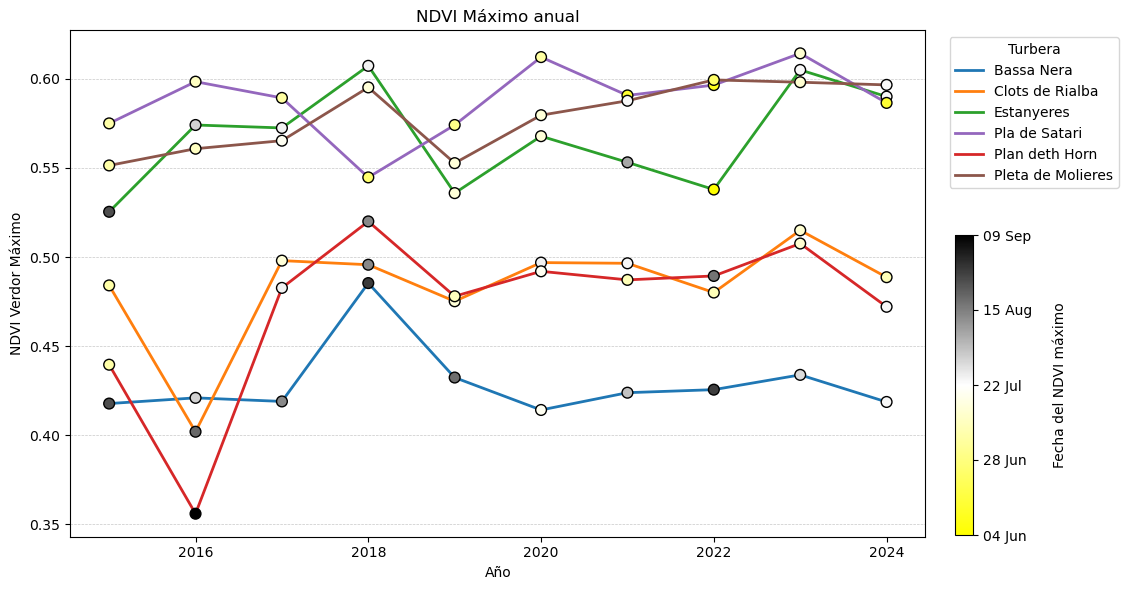

In [101]:
"""
import os
import pandas as pd
import matplotlib.pyplot as plt

# Directorio de entrada y salida
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"
output_path = os.path.join(input_dir, "grafico_media_NDVI_turberas.png")

# Leer todos los CSV y combinarlos
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Pivotear para gráfico: Media NDVI por año y turbera
pivot = df_total.pivot(index="YEAR", columns="Turbera", values="MEDIA NDVI")

# Colores personalizados por turbera (ajustar según nombres reales)
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Crear gráfico
ax = pivot.plot(kind="bar", figsize=(10, 5), color=[colores.get(col, "#333333") for col in pivot.columns], alpha=0.8)

# Personalización de ejes y leyenda
plt.title("Media Anual de NDVI", fontsize=13, pad=15)
plt.xlabel("Año", fontsize=11)
plt.ylabel("Media NDVI", fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda dentro del gráfico, ajustada
plt.legend(title="Turbera", loc="upper left", bbox_to_anchor=(0, 0.40), fontsize=8, frameon=True, framealpha=0.95)

# Layout para evitar cortes
plt.tight_layout(rect=[0, 0.1, 1, 1])

# Guardar gráfico
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Gráfico guardado en: {output_path}")


#----------------------------------------------------
# Segundo gráfico: duración del período de verdor (columna "Periodo")
#----------------------------------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt

# Directorio con los CSV NDVI
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"
output_path = os.path.join(input_dir, "grafico_periodo_verdor_turberas.png")

# Leer y combinar todos los CSV
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Pivotear para gráfico: duración del verdor
pivot_verdor = df_total.pivot(index="YEAR", columns="Turbera", values="Periodo Verdor")

# Colores personalizados
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Crear gráfico
fig, ax = plt.subplots(figsize=(10, 5))

pivot_verdor.plot(
    kind='bar',
    ax=ax,
    color=[colores.get(col, "#333333") for col in pivot_verdor.columns],
    alpha=0.8,
    width=0.5
)

# Etiquetas y formato
ax.set_title("Duración del Período de Verdor", fontsize=13, pad=15)
ax.set_xlabel("Año", fontsize=11)
ax.set_ylabel("Duración (días)", fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)

# Leyenda
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.40),
    fontsize=8,
    frameon=True,
    framealpha=0.95
)

# Cuadrícula horizontal
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Ajustes finales
plt.tight_layout(rect=[0, 0.1, 1, 1])

# Guardar imagen
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Gráfico guardado en: {output_path}")


#----------------------------------------------------
# Gráfico de líneas: duración del período de verdor por temporada y turbera
#----------------------------------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt

# Ruta
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"

# Leer todos los archivos NDVI
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Pivotear para gráfico de líneas
pivot_duracion = df_total.pivot(index="YEAR", columns="Turbera", values="Periodo Verdor")

# Colores por turbera
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Crear figura
fig, ax = plt.subplots(figsize=(10, 5))

# Dibujar cada turbera: línea + puntos
for turbera in pivot_duracion.columns:
    ax.plot(
        pivot_duracion.index,
        pivot_duracion[turbera],
        label=turbera,
        color=colores.get(turbera, None),
        linewidth=2,
        alpha=0.6
    )
    ax.scatter(
        pivot_duracion.index,
        pivot_duracion[turbera],
        color=colores.get(turbera, None),
        edgecolor='black',
        zorder=3,
        alpha=1,
        s=40
    )

# Ejes y título
ax.set_title("Duración del Período de Verdor")
ax.set_xlabel("Temporada")
ax.set_ylabel("Duración del Período (días)")
ax.set_xticks(pivot_duracion.index)
ax.set_xticklabels(pivot_duracion.index, rotation=45)

# Cuadrícula horizontal
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda dentro del gráfico
plt.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.35),
    fontsize=8,
    frameon=True,
    framealpha=0.95
)

# Ajustar y guardar
plt.tight_layout()
plt.savefig(os.path.join(input_dir, "grafico_periodo_verdor_lineas_turberas.png"), dpi=150, bbox_inches='tight')
plt.show()

#----------------------------------------------------
# Gráfico de líneas suavizadas: duración del período de verdor por turbera
#----------------------------------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
import numpy as np

# Ruta
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"

# Leer todos los archivos NDVI
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Pivotear para gráfico
pivot_duracion = df_total.pivot(index="YEAR", columns="Turbera", values="Periodo Verdor")

# Colores por turbera
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Crear figura
fig, ax = plt.subplots(figsize=(10, 5))

# Eje x numérico para interpolación
x_numeric = np.arange(len(pivot_duracion.index))
x_labels = pivot_duracion.index

# Dibujar suavizado por turbera
for turbera in pivot_duracion.columns:
    y = pivot_duracion[turbera].values

    # Eliminar NaN
    mask = ~np.isnan(y)
    x_vals = x_numeric[mask]
    y_vals = y[mask]

    if len(x_vals) >= 4:
        spline = make_interp_spline(x_vals, y_vals, k=2)
        x_smooth = np.linspace(x_vals.min(), x_vals.max(), 100)
        y_smooth = spline(x_smooth)
        ax.plot(x_smooth, y_smooth, color=colores.get(turbera, None), label=turbera, alpha=0.6)
    else:
        ax.plot(x_vals, y_vals, color=colores.get(turbera, None), label=turbera, alpha=0.6)

    # Puntos reales
    ax.scatter(x_vals, y_vals, color=colores.get(turbera, None), edgecolor='black', zorder=3, s=45)

# Ejes y etiquetas
ax.set_title("Duración del Período de Verdor (Suavizado)")
ax.set_xlabel("Temporada")
ax.set_ylabel("Duración del Período (días)")
ax.set_xticks(x_numeric)
ax.set_xticklabels(x_labels, rotation=45)

# Cuadrícula y leyenda
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left')
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.35),
    fontsize=8,
    frameon=True,
    framealpha=0.95
)

# Ajustar y guardar
plt.tight_layout()
plt.savefig(os.path.join(input_dir, "grafico_periodo_verdor_lineas_suavizadas_turberas.png"), dpi=150, bbox_inches='tight')
plt.show()


#----------------------------------------------------
# Gráfico de verdor maximo
#----------------------------------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Ruta de entrada y salida
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"
output_path = os.path.join(input_dir, "grafico_ndvi_max_turberas.png")

# Colores por turbera
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Leer todos los CSV y combinarlos
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Convertir YEAR a numérico si es necesario
df_total["YEAR"] = pd.to_numeric(df_total["YEAR"], errors="coerce")

# Pivotear
pivot_ndvi_max = df_total.pivot(index="YEAR", columns="Turbera", values="NDVI Verdor Max")

# Crear gráfico
fig, ax = plt.subplots(figsize=(10, 5))

x_numeric = pivot_ndvi_max.index

for turbera in pivot_ndvi_max.columns:
    y = pivot_ndvi_max[turbera].values

    # Evitar errores por valores NaN
    mask = ~np.isnan(y)
    x_vals = x_numeric[mask]
    y_vals = y[mask]

    ax.plot(
        x_vals, y_vals,
        label=turbera,
        color=colores.get(turbera, None),
        linewidth=2,
        alpha=0.7
    )

    ax.scatter(
        x_vals, y_vals,
        color=colores.get(turbera, None),
        edgecolor='black',
        s=45,
        zorder=3
    )

# Estética
ax.set_title("NDVI Máximo Anual")
ax.set_xlabel("Año")
ax.set_ylabel("NDVI Verdor Máximo")
ax.set_xticks(pivot_ndvi_max.index)
ax.set_xticklabels(pivot_ndvi_max.index, rotation=45)
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda dentro del gráfico
plt.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.35),
    fontsize=8,
    frameon=True,
    framealpha=0.95
)

plt.tight_layout()
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()

#----------------------------------------------------
# Gráfico de verdor maximo y su FECHA SUBPLOT
#----------------------------------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt

# === Ruta de entrada y salida ===
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"
output_path = os.path.join(input_dir, "grafico_ndvi_max_subplots.png")

# === Leer todos los archivos _analisis_NDVI.csv ===
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        df["Verdor Max"] = pd.to_datetime(df["Verdor Max"], errors="coerce")
        df["Día Juliano"] = df["Verdor Max"].dt.dayofyear
        dfs.append(df)

df_total = pd.concat(dfs)

# === Colores fijos por turbera ===
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# === Crear figura con subplots sincronizados ===
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

# === Gráfico superior: NDVI máximo anual ===
for turbera, grupo in df_total.groupby("Turbera"):
    ax1.plot(grupo["YEAR"], grupo["NDVI Verdor Max"], label=turbera, color=colores.get(turbera), linewidth=2)
    ax1.scatter(grupo["YEAR"], grupo["NDVI Verdor Max"], color=colores.get(turbera), edgecolor='black', s=40)

ax1.set_ylabel("NDVI Verdor Máximo")
ax1.set_title("NDVI Máximo Anual por Turbera")
ax1.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# === Gráfico inferior: Día Juliano del Verdor Máximo ===
for turbera, grupo in df_total.groupby("Turbera"):
    ax2.plot(grupo["YEAR"], grupo["Día Juliano"], label=turbera, color=colores.get(turbera), linestyle='--', linewidth=1.5, alpha=0.7)
    ax2.scatter(grupo["YEAR"], grupo["Día Juliano"], color=colores.get(turbera), edgecolor='black', s=40)

ax2.set_ylabel("Día Juliano")
ax2.set_xlabel("Año")
ax2.set_title("Fecha del Verdor Máximo (Día Juliano)")
ax2.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# === Leyenda combinada (una sola vez) ===
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, title="Turbera", loc='center left', bbox_to_anchor=(0.88, 0.5), frameon=True)

# === Ajustar layout y guardar ===
plt.tight_layout(rect=[0, 0, 0.86, 1])  # deja espacio a la derecha para la leyenda
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()


#----------------------------------------------------
# Gráfico de verdor maximo y su FECHA etiqueta
#----------------------------------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt

# Rutas
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"

# Colores fijos
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Leer y combinar archivos
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Convertir fechas y extraer día juliano
df_total["Verdor Max"] = pd.to_datetime(df_total["Verdor Max"], errors="coerce")
df_total["Día Juliano"] = df_total["Verdor Max"].dt.dayofyear

# Graficar
fig, ax = plt.subplots(figsize=(12, 6))

for turbera, grupo in df_total.groupby("Turbera"):
    ax.plot(grupo["YEAR"], grupo["NDVI Verdor Max"], label=turbera, color=colores.get(turbera), linewidth=2, marker='o')
    
    for _, row in grupo.iterrows():
        if pd.notna(row["Día Juliano"]):
            ax.annotate(
                f"{int(row['Día Juliano'])}",
                (row["YEAR"], row["NDVI Verdor Max"]),
                textcoords="offset points",
                xytext=(0, 5),
                ha='center',
                fontsize=8
            )

# Estética
ax.set_title("NDVI Máximo Anual por Turbera (con Día Juliano del Verdor Max)")
ax.set_xlabel("Año")
ax.set_ylabel("NDVI Verdor Máximo")
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)
ax.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left')

# Layout y guardar
plt.tight_layout()
plt.savefig(os.path.join(input_dir, "grafico_ndvi_max_con_dia_juliano.png"), dpi=150, bbox_inches='tight')
plt.show()

#----------------------------------------------------
# Gráfico de verdor máximo y su FECHA coloreado
#----------------------------------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from datetime import datetime, timedelta  # ✅ IMPORTACIÓN CLAVE

# Ruta
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"

# Colores de línea por turbera
colores_linea = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Leer archivos
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Convertir fechas y calcular día juliano
df_total["Verdor Max"] = pd.to_datetime(df_total["Verdor Max"], errors="coerce")
df_total["Día Juliano"] = df_total["Verdor Max"].dt.dayofyear

# Rango real de días julianos
vmin = df_total["Día Juliano"].min()
vmax = df_total["Día Juliano"].max()

# Crear gráfico
fig, ax = plt.subplots(figsize=(12, 6))

# Colormap
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.cm.seismic
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Dibujar líneas y puntos codificados por color
for turbera, grupo in df_total.groupby("Turbera"):
    ax.plot(grupo["YEAR"], grupo["NDVI Verdor Max"], label=turbera, color=colores_linea.get(turbera), linewidth=2)
    ax.scatter(
        grupo["YEAR"],
        grupo["NDVI Verdor Max"],
        c=grupo["Día Juliano"],
        cmap=cmap,
        norm=norm,
        edgecolor='black',
        s=60,
        zorder=3
    )

# Etiquetas
ax.set_title("NDVI Máximo Anual por Turbera (color indica día juliano del Verdor Max)")
ax.set_xlabel("Año")
ax.set_ylabel("NDVI Verdor Máximo")
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda
ax.legend(title="Turbera", loc='upper left', bbox_to_anchor=(1.02, 1))

# Barra de color horizontal debajo del gráfico
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal", pad=0.2)
cbar.set_label("Día Juliano del Verdor Máximo")

# Etiquetas de la barra en formato fecha
dia_juliano_total = df_total["Día Juliano"].dropna().values
ticks = np.linspace(np.nanmin(dia_juliano_total), np.nanmax(dia_juliano_total), 5)
cbar.set_ticks(ticks)
cbar.set_ticklabels([
    (datetime(2020, 1, 1) + timedelta(days=int(d))).strftime('%d %b')
    for d in ticks
])

# Ajustar y guardar
plt.tight_layout()
plt.savefig(os.path.join(input_dir, "grafico_ndvi_max_coloreado_dia_juliano_v2.png"), dpi=150, bbox_inches='tight')
plt.show()

#----------------------------------------------------
# Gráfico de verdor máximo y su FECHA coloreado (ajustado)
#----------------------------------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from datetime import datetime, timedelta  # ✅ Importación clave

# Ruta
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"

# Colores de línea por turbera
colores_linea = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Leer archivos
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Convertir fechas y calcular día juliano
df_total["Verdor Max"] = pd.to_datetime(df_total["Verdor Max"], errors="coerce")
df_total["Día Juliano"] = df_total["Verdor Max"].dt.dayofyear

# Rango real de días julianos
vmin = df_total["Día Juliano"].min()
vmax = df_total["Día Juliano"].max()

# Crear gráfico
fig, ax = plt.subplots(figsize=(12, 6))

# Colormap
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.cm.seismic
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Dibujar líneas y puntos codificados por color
for turbera, grupo in df_total.groupby("Turbera"):
    ax.plot(grupo["YEAR"], grupo["NDVI Verdor Max"], label=turbera, color=colores_linea.get(turbera), linewidth=2)
    ax.scatter(
        grupo["YEAR"],
        grupo["NDVI Verdor Max"],
        c=grupo["Día Juliano"],
        cmap=cmap,
        norm=norm,
        edgecolor='black',
        s=60,
        zorder=3
    )

# Etiquetas
ax.set_title("NDVI Máximo anual")
ax.set_xlabel("Año")
ax.set_ylabel("NDVI Verdor Máximo")
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda
ax.legend(title="Turbera", loc='upper left', bbox_to_anchor=(1.02, 1))

# Barra de color horizontal (más cerca y más fina)
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal", pad=0.05, shrink=0.5)
cbar.set_label("Fecha del NDVI máximo")

# Etiquetas de la barra con fechas reales
dia_juliano_total = df_total["Día Juliano"].dropna().values
ticks = np.linspace(np.nanmin(dia_juliano_total), np.nanmax(dia_juliano_total), 5)
cbar.set_ticks(ticks)
cbar.set_ticklabels([
    (datetime(2020, 1, 1) + timedelta(days=int(d))).strftime('%d %b')
    for d in ticks
])

# Ajustar y guardar
plt.tight_layout()
plt.savefig(os.path.join(input_dir, "grafico_ndvi_max_coloreado_dia_juliano_v3.png"), dpi=150, bbox_inches='tight')
plt.show()
"""
#----------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from datetime import datetime, timedelta

# Ruta a los archivos
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDVI"

# Colores de línea por turbera
colores_linea = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Leer archivos CSV
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDVI.csv"):
        nombre = file.replace("_analisis_NDVI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Convertir fecha y calcular día juliano
df_total["Verdor Max"] = pd.to_datetime(df_total["Verdor Max"], errors="coerce")
df_total["Día Juliano"] = df_total["Verdor Max"].dt.dayofyear

# Rango para colormap
vmin = df_total["Día Juliano"].min()
vmax = df_total["Día Juliano"].max()

# Normalización y colormap azul-rojo
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

from matplotlib.colors import LinearSegmentedColormap

# Define colores extremos
colors = ["#FFFF00", "white", "#000000"]  # azul → blanco → rojo
cmap = LinearSegmentedColormap.from_list("mi_mapa", colors)


sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Crear gráfico
fig, ax = plt.subplots(figsize=(12, 6))

# Dibujar líneas y puntos coloreados
for turbera, grupo in df_total.groupby("Turbera"):
    ax.plot(grupo["YEAR"], grupo["NDVI Verdor Max"],
            label=turbera,
            color=colores_linea.get(turbera, "gray"),
            linewidth=2)
    ax.scatter(grupo["YEAR"], grupo["NDVI Verdor Max"],
               c=grupo["Día Juliano"],
               cmap=cmap,
               norm=norm,
               edgecolor='black',
               s=60,
               zorder=3)

# Estética
ax.set_title("NDVI Máximo anual")
ax.set_xlabel("Año")
ax.set_ylabel("NDVI Verdor Máximo")
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda
ax.legend(title="Turbera", loc='upper left', bbox_to_anchor=(1.02, 1))

# Colormap: barra vertical debajo de la leyenda
cbar_ax = fig.add_axes([0.8, 0.1, 0.015, 0.5])  # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("Fecha del NDVI máximo", labelpad=15)

# Etiquetas de fecha en la barra
dia_juliano_total = df_total["Día Juliano"].dropna().values
ticks = np.linspace(np.nanmin(dia_juliano_total), np.nanmax(dia_juliano_total), 5)
cbar.set_ticks(ticks)
cbar.set_ticklabels([
    (datetime(2020, 1, 1) + timedelta(days=int(d))).strftime('%d %b')  # Salto de línea
    for d in ticks
])

# Ajuste final
plt.tight_layout(rect=[0, 0, 0.95, 1])
plt.savefig(os.path.join(input_dir, "grafico_ndvi_max_coloreado_dia_juliano_v4.png"), dpi=150, bbox_inches='tight')
plt.show()

